In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the datasets
train_transaction = pd.read_csv("train_transaction.csv")
train_identity = pd.read_csv("train_identity.csv")

print("Transaction data shape:", train_transaction.shape)
print("Identity data shape:", train_identity.shape)

In [ ]:
# Look at the first 5 rows of transaction data
print("=== TRANSACTION DATA ===")
print(train_transaction.head())

print("\n=== IDENTITY DATA ===")
print(train_identity.head())

print("\n=== TRANSACTION COLUMNS ===")
print(train_transaction.columns.tolist())

=== TRANSACTION DATA ===
   TransactionID  isFraud  TransactionDT  TransactionAmt ProductCD  card1  \
0        2987000        0          86400            68.5         W  13926   
1        2987001        0          86401            29.0         W   2755   
2        2987002        0          86469            59.0         W   4663   
3        2987003        0          86499            50.0         W  18132   
4        2987004        0          86506            50.0         H   4497   

   card2  card3       card4  card5  ... V330  V331  V332  V333  V334 V335  \
0    NaN  150.0    discover  142.0  ...  NaN   NaN   NaN   NaN   NaN  NaN   
1  404.0  150.0  mastercard  102.0  ...  NaN   NaN   NaN   NaN   NaN  NaN   
2  490.0  150.0        visa  166.0  ...  NaN   NaN   NaN   NaN   NaN  NaN   
3  567.0  150.0  mastercard  117.0  ...  NaN   NaN   NaN   NaN   NaN  NaN   
4  514.0  150.0  mastercard  102.0  ...  0.0   0.0   0.0   0.0   0.0  0.0   

  V336  V337  V338  V339  
0  NaN   NaN   NaN   N

isFraud
0    569877
1     20663
Name: count, dtype: int64

Fraud percentage: 3.50%


C:\Users\sanu varghese\AppData\Local\Temp\ipykernel_5272\1193507848.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='isFraud', data=train_transaction, palette=['steelblue','red'])


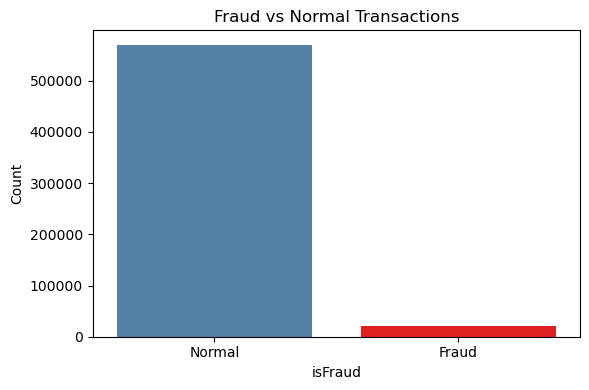

In [ ]:
# How many fraud vs normal transactions?
fraud_count = train_transaction['isFraud'].value_counts()
print(fraud_count)

# What percentage is fraud?
fraud_percent = train_transaction['isFraud'].mean() * 100
print(f"\nFraud percentage: {fraud_percent:.2f}%")

# Visualise it
plt.figure(figsize=(6,4))
sns.countplot(x='isFraud', data=train_transaction, palette=['steelblue','red'])
plt.title('Fraud vs Normal Transactions')
plt.xticks([0,1], ['Normal', 'Fraud'])
plt.ylabel('Count')
plt.tight_layout()
plt.show()

In [ ]:
# Basic info about transaction amounts
print("=== TRANSACTION AMOUNT STATS ===")
print(train_transaction['TransactionAmt'].describe())

print("\n=== FRAUD TRANSACTION AMOUNT STATS ===")
print(train_transaction[train_transaction['isFraud']==1]['TransactionAmt'].describe())

print("\n=== NORMAL TRANSACTION AMOUNT STATS ===")
print(train_transaction[train_transaction['isFraud']==0]['TransactionAmt'].describe())


=== TRANSACTION AMOUNT STATS ===
count    590540.000000
mean        135.027176
std         239.162522
min           0.251000
25%          43.321000
50%          68.769000
75%         125.000000
max       31937.391000
Name: TransactionAmt, dtype: float64

=== FRAUD TRANSACTION AMOUNT STATS ===
count    20663.000000
mean       149.244779
std        232.212163
min          0.292000
25%         35.044000
50%         75.000000
75%        161.000000
max       5191.000000
Name: TransactionAmt, dtype: float64

=== NORMAL TRANSACTION AMOUNT STATS ===
count    569877.000000
mean        134.511665
std         239.395078
min           0.251000
25%          43.970000
50%          68.500000
75%         120.000000
max       31937.391000
Name: TransactionAmt, dtype: float64


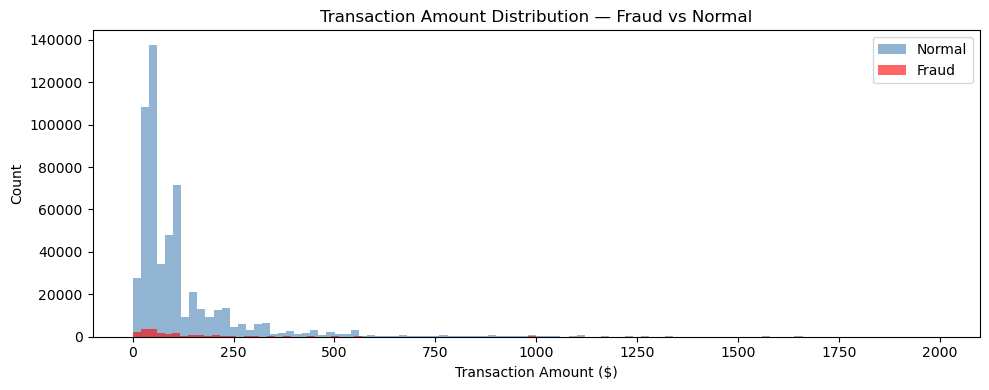

In [ ]:
# Compare fraud vs normal transaction amounts visually
plt.figure(figsize=(10, 4))

# We limit to amounts under 2000 so the chart is readable
normal = train_transaction[train_transaction['isFraud']==0]['TransactionAmt']
fraud = train_transaction[train_transaction['isFraud']==1]['TransactionAmt']

plt.hist(normal[normal < 2000], bins=100, alpha=0.6, color='steelblue', label='Normal')
plt.hist(fraud[fraud < 2000], bins=100, alpha=0.6, color='red', label='Fraud')

plt.title('Transaction Amount Distribution — Fraud vs Normal')
plt.xlabel('Transaction Amount ($)')
plt.ylabel('Count')
plt.legend()
plt.tight_layout()
plt.show()

ProductCD
C    11.687269
S     5.899553
H     4.766231
R     3.782594
W     2.039939
Name: isFraud, dtype: float64


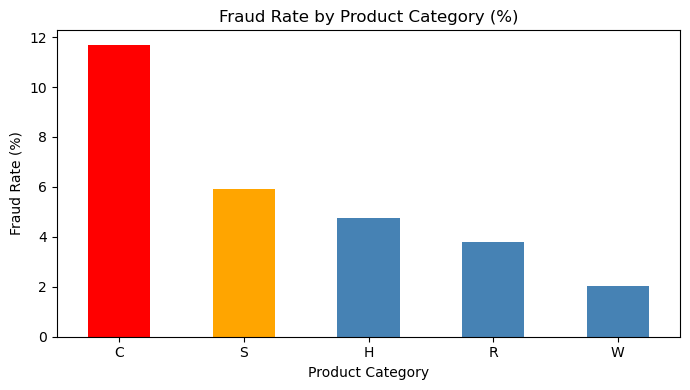

In [ ]:
# Fraud rate by product category
product_fraud = train_transaction.groupby('ProductCD')['isFraud'].mean() * 100
product_fraud = product_fraud.sort_values(ascending=False)
print(product_fraud)

# Visualise
plt.figure(figsize=(7, 4))
product_fraud.plot(kind='bar', color=['red','orange','steelblue','steelblue','steelblue'])
plt.title('Fraud Rate by Product Category (%)')
plt.xlabel('Product Category')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

card4
discover            7.728161
visa                3.475610
mastercard          3.433095
american express    2.869837
Name: isFraud, dtype: float64


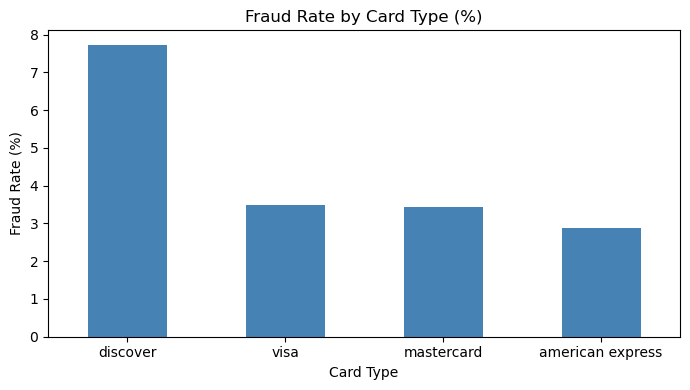

In [ ]:
# Fraud rate by card type (Visa, Mastercard etc.)
card_fraud = train_transaction.groupby('card4')['isFraud'].mean() * 100
card_fraud = card_fraud.sort_values(ascending=False)
print(card_fraud)

plt.figure(figsize=(7, 4))
card_fraud.plot(kind='bar', color='steelblue')
plt.title('Fraud Rate by Card Type (%)')
plt.xlabel('Card Type')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Check missing values
missing = train_transaction.isnull().sum()
missing_percent = (missing / len(train_transaction)) * 100

# Only show columns that actually have missing values
missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_percent
})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)

print(f"Total columns with missing values: {len(missing_df)}")
print(f"Total columns: {train_transaction.shape[1]}")
print("\nTop 20 columns with most missing data:")
print(missing_df.head(20))

Total columns with missing values: 374
Total columns: 394

Top 20 columns with most missing data:
       Missing Count  Missing %
dist2         552913  93.628374
D7            551623  93.409930
D13           528588  89.509263
D14           528353  89.469469
D12           525823  89.041047
D6            517353  87.606767
D9            515614  87.312290
D8            515614  87.312290
V157          508595  86.123717
V163          508595  86.123717
V162          508595  86.123717
V161          508595  86.123717
V158          508595  86.123717
V153          508595  86.123717
V138          508595  86.123717
V155          508595  86.123717
V154          508595  86.123717
V149          508595  86.123717
V148          508595  86.123717
V147          508595  86.123717


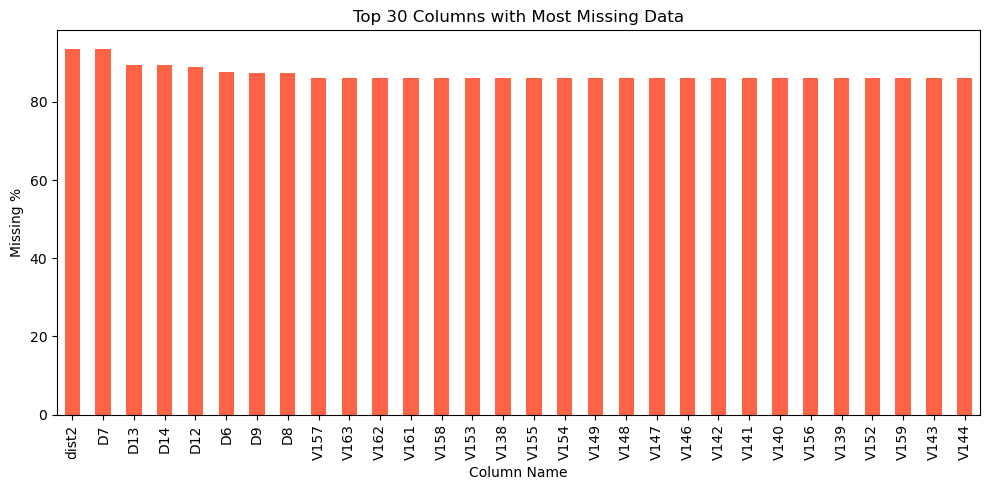

Missing data summary:
Columns with >80% missing: 55
Columns with 50–80% missing: 119
Columns with <50% missing: 200


In [ ]:
# Visualise missing data
plt.figure(figsize=(10, 5))
missing_df['Missing %'].head(30).plot(kind='bar', color='tomato')
plt.title('Top 30 Columns with Most Missing Data')
plt.xlabel('Column Name')
plt.ylabel('Missing %')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# How many columns fall in each missing % range?
print("Missing data summary:")
print(f"Columns with >80% missing: {len(missing_df[missing_df['Missing %'] > 80])}")
print(f"Columns with 50–80% missing: {len(missing_df[(missing_df['Missing %'] > 50) & (missing_df['Missing %'] <= 80)])}")
print(f"Columns with <50% missing: {len(missing_df[missing_df['Missing %'] <= 50])}")

In [ ]:
# Merge transaction and identity data
df = train_transaction.merge(train_identity, on='TransactionID', how='left')

print("Merged data shape:", df.shape)
print("isFraud column still present:", 'isFraud' in df.columns)

Merged data shape: (590540, 434)
isFraud column still present: True


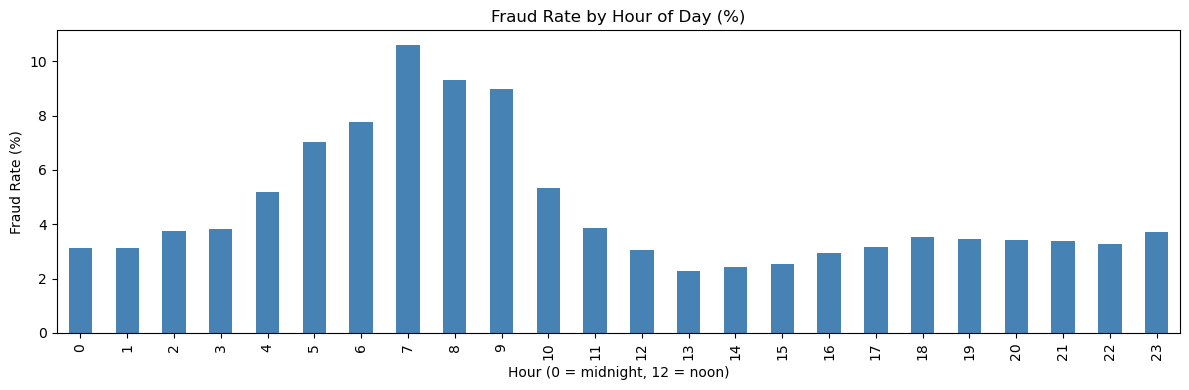

New features added: hour, day


In [ ]:
# Extract time features from TransactionDT
df['hour'] = (df['TransactionDT'] / 3600) % 24  # hour of day (0-23)
df['day'] = (df['TransactionDT'] / (3600 * 24)) % 7  # day of week (0-6)

# Check fraud rate by hour
hourly_fraud = df.groupby(df['hour'].astype(int))['isFraud'].mean() * 100

plt.figure(figsize=(12, 4))
hourly_fraud.plot(kind='bar', color='steelblue')
plt.title('Fraud Rate by Hour of Day (%)')
plt.xlabel('Hour (0 = midnight, 12 = noon)')
plt.ylabel('Fraud Rate (%)')
plt.tight_layout()
plt.show()

print("New features added: hour, day")

In [ ]:
# For each card1, calculate average and max transaction amount
card_stats = df.groupby('card1')['TransactionAmt'].agg(['mean', 'max', 'count'])
card_stats.columns = ['card1_avg_amt', 'card1_max_amt', 'card1_txn_count']

# Add these back to our main dataframe
df = df.merge(card_stats, on='card1', how='left')

# Create a new feature — how different is this transaction from the card's average?
df['amt_diff_from_avg'] = df['TransactionAmt'] - df['card1_avg_amt']
df['amt_ratio_to_avg'] = df['TransactionAmt'] / (df['card1_avg_amt'] + 1)

print("New features added!")
print(df[['TransactionAmt', 'card1_avg_amt', 'amt_diff_from_avg', 'amt_ratio_to_avg']].head(10))

New features added!
   TransactionAmt  card1_avg_amt  amt_diff_from_avg  amt_ratio_to_avg
0            68.5     351.931163        -283.431163          0.194089
1            29.0     234.292753        -205.292753          0.123251
2            59.0      97.015542         -38.015542          0.601945
3            50.0     123.416340         -73.416340          0.401876
4            50.0      96.972222         -46.972222          0.510349
5            49.0     134.071429         -85.071429          0.362771
6           159.0     101.880097          57.119903          1.545488
7           422.5     141.144645         281.355355          2.972324
8            15.0     142.683409        -127.683409          0.104396
9           117.0     122.020491          -5.020491          0.951061


In [ ]:
# card1_txn_count was already created above - let's check it
print(df[['card1', 'card1_txn_count']].drop_duplicates().sort_values('card1_txn_count', ascending=False).head(10))

# Create a feature: is this a low-frequency (rare) card?
df['is_rare_card'] = (df['card1_txn_count'] < 5).astype(int)

print("\nHow many transactions are from rare cards (used less than 5 times)?")
print(df['is_rare_card'].value_counts())

print("\nFraud rate for rare cards vs frequent cards:")
print(df.groupby('is_rare_card')['isFraud'].mean() * 100)

     card1  card1_txn_count
526   7919            14932
107   9500            14162
48   15885            10361
65   17188            10344
82   15066             7945
7    12695             7091
46   12544             6773
167   6019             6771
8     2803             6141
286   7585             5334

How many transactions are from rare cards (used less than 5 times)?
is_rare_card
0    577192
1     13348
Name: count, dtype: int64

Fraud rate for rare cards vs frequent cards:
is_rare_card
0    3.501608
1    3.386275
Name: isFraud, dtype: float64


In [ ]:
# Fraud rate by purchaser email domain
email_fraud = df.groupby('P_emaildomain')['isFraud'].agg(['mean', 'count'])
email_fraud.columns = ['fraud_rate', 'count']
email_fraud['fraud_rate'] = email_fraud['fraud_rate'] * 100

# Only look at email domains with at least 500 transactions (so it's reliable)
email_fraud_reliable = email_fraud[email_fraud['count'] >= 500].sort_values('fraud_rate', ascending=False)

print(email_fraud_reliable.head(15))

               fraud_rate   count
P_emaildomain                    
mail.com        18.962433     559
outlook.com      9.458399    5096
live.com.mx      5.473965     749
hotmail.com      5.295028   45250
gmail.com        4.354185  228355
icloud.com       3.143450    6267
comcast.net      3.118661    7888
charter.net      3.063725     816
bellsouth.net    2.776323    1909
live.com         2.762249    3041
anonymous.com    2.321747   36998
yahoo.com        2.275745  100934
msn.com          2.199413    4092
aol.com          2.181060   28289
earthlink.net    2.140078     514


In [ ]:
# Map each email domain to its fraud rate (this becomes a powerful numeric feature)
email_risk_map = email_fraud['fraud_rate'].to_dict()
df['email_risk_score'] = df['P_emaildomain'].map(email_risk_map)

# Fill missing emails with the average fraud rate
df['email_risk_score'] = df['email_risk_score'].fillna(df['isFraud'].mean() * 100)

print("Email risk score feature created!")
print(df[['P_emaildomain', 'email_risk_score']].head(10))

Email risk score feature created!
   P_emaildomain  email_risk_score
0            NaN          3.499001
1      gmail.com          4.354185
2    outlook.com          9.458399
3      yahoo.com          2.275745
4      gmail.com          4.354185
5      gmail.com          4.354185
6      yahoo.com          2.275745
7       mail.com         18.962433
8  anonymous.com          2.321747
9      yahoo.com          2.275745


In [ ]:
# Drop columns with >80% missing values (too empty to be useful)
missing_percent_full = (df.isnull().sum() / len(df)) * 100
cols_to_drop = missing_percent_full[missing_percent_full > 80].index.tolist()

print(f"Dropping {len(cols_to_drop)} columns with >80% missing values...")
df = df.drop(columns=cols_to_drop)

# Also drop columns we've replaced with better features
df = df.drop(columns=['TransactionDT', 'P_emaildomain'], errors='ignore')

print("New shape after dropping columns:", df.shape)

Dropping 74 columns with >80% missing values...
New shape after dropping columns: (590540, 367)


In [ ]:
# Separate numeric and categorical columns
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

# Remove isFraud and TransactionID from numeric list (we don't want to fill these)
numeric_cols = [col for col in numeric_cols if col not in ['isFraud', 'TransactionID']]

print(f"Numeric columns: {len(numeric_cols)}")
print(f"Categorical columns: {len(categorical_cols)}")

# Fill numeric missing values with -999 (a common trick - tells the model "this was missing")
df[numeric_cols] = df[numeric_cols].fillna(-999)

# Fill categorical missing values with 'missing' as a category
df[categorical_cols] = df[categorical_cols].fillna('missing')

print("\nMissing values remaining:", df.isnull().sum().sum())

Numeric columns: 339
Categorical columns: 25

Missing values remaining: 0


In [ ]:
from sklearn.preprocessing import LabelEncoder

# Encode all categorical columns
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le  # save it in case we need to decode later

print("All categorical columns encoded!")
print(df[categorical_cols].head())

All categorical columns encoded!
   ProductCD  card4  card6  R_emaildomain  M1  M2  M3  M4  M5  M6  ...  id_16  \
0          4      1      1             25   1   1   1   2   0   1  ...      2   
1          4      2      1             25   2   2   2   0   1   1  ...      2   
2          4      4      2             25   1   1   1   0   0   0  ...      2   
3          4      2      2             25   2   2   2   0   1   0  ...      2   
4          1      2      1             25   2   2   2   3   2   2  ...      1   

   id_28  id_29  id_31  id_35  id_36  id_37  id_38  DeviceType  DeviceInfo  
0      2      2    127      2      2      2      2           1         819  
1      2      2    127      2      2      2      2           1         819  
2      2      2    127      2      2      2      2           1         819  
3      2      2    127      2      2      2      2           1         819  
4      1      1     29      1      0      1      1           2        1737  

[5 rows x 25 colu

In [ ]:
# Save the cleaned dataset
df.to_csv('cleaned_fraud_data.csv', index=False)
print("Saved! File size and shape:", df.shape)

Saved! File size and shape: (590540, 367)


In [ ]:
from sklearn.model_selection import train_test_split

# Separate features (X) from target (y)
X = df.drop(columns=['isFraud', 'TransactionID'])
y = df['isFraud']

# Split into 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)
print("\nFraud % in training set:", y_train.mean() * 100)
print("Fraud % in testing set:", y_test.mean() * 100)

Training set shape: (472432, 365)
Testing set shape: (118108, 365)

Fraud % in training set: 3.498916246147594
Fraud % in testing set: 3.49933958749619


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Train a simple baseline model
baseline_model = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
baseline_model.fit(X_train, y_train)

# Predict on test set
y_pred = baseline_model.predict(X_test)
y_pred_proba = baseline_model.predict_proba(X_test)[:, 1]

# Evaluate
print("=== BASELINE MODEL RESULTS ===")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")

=== BASELINE MODEL RESULTS ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.99    113975
           1       0.93      0.27      0.41      4133

    accuracy                           0.97    118108
   macro avg       0.95      0.63      0.70    118108
weighted avg       0.97      0.97      0.97    118108

ROC-AUC Score: 0.8683


In [ ]:
# Train again, but tell the model fraud cases are important
weighted_model = RandomForestClassifier(
    n_estimators=50, 
    max_depth=10, 
    random_state=42, 
    n_jobs=-1,
    class_weight='balanced'  # this is the key change!
)
weighted_model.fit(X_train, y_train)

y_pred_w = weighted_model.predict(X_test)
y_pred_proba_w = weighted_model.predict_proba(X_test)[:, 1]

print("=== CLASS-WEIGHTED MODEL RESULTS ===")
print(classification_report(y_test, y_pred_w))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_w):.4f}")

=== CLASS-WEIGHTED MODEL RESULTS ===
              precision    recall  f1-score   support

           0       0.99      0.88      0.93    113975
           1       0.19      0.74      0.30      4133

    accuracy                           0.88    118108
   macro avg       0.59      0.81      0.62    118108
weighted avg       0.96      0.88      0.91    118108

ROC-AUC Score: 0.8897


In [ ]:
import xgboost as xgb

# Calculate the right scale_pos_weight for imbalance
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Scale pos weight: {scale_pos_weight:.2f}")

xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='auc',
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)
y_pred_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("=== XGBOOST MODEL RESULTS ===")
print(classification_report(y_test, y_pred_xgb))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_xgb):.4f}")

Scale pos weight: 27.58
=== XGBOOST MODEL RESULTS ===
              precision    recall  f1-score   support

           0       0.99      0.92      0.95    113975
           1       0.26      0.82      0.39      4133

    accuracy                           0.91    118108
   macro avg       0.63      0.87      0.67    118108
weighted avg       0.97      0.91      0.93    118108

ROC-AUC Score: 0.9419


In [ ]:
import sys
print(sys.executable)

c:\Users\sanu varghese\anaconda3\python.exe


In [ ]:
import lightgbm as lgb

lgb_model = lgb.LGBMClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

lgb_model.fit(X_train, y_train)

y_pred_lgb = lgb_model.predict(X_test)
y_pred_proba_lgb = lgb_model.predict_proba(X_test)[:, 1]

print("=== LIGHTGBM MODEL RESULTS ===")
print(classification_report(y_test, y_pred_lgb))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_lgb):.4f}")

=== LIGHTGBM MODEL RESULTS ===
              precision    recall  f1-score   support

           0       0.99      0.91      0.95    113975
           1       0.24      0.82      0.37      4133

    accuracy                           0.90    118108
   macro avg       0.62      0.86      0.66    118108
weighted avg       0.97      0.90      0.93    118108

ROC-AUC Score: 0.9366


In [ ]:
# Average the predictions from XGBoost and LightGBM
ensemble_proba = (y_pred_proba_xgb + y_pred_proba_lgb) / 2
ensemble_pred = (ensemble_proba >= 0.5).astype(int)

print("=== ENSEMBLE MODEL RESULTS (XGBoost + LightGBM) ===")
print(classification_report(y_test, ensemble_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, ensemble_proba):.4f}")

=== ENSEMBLE MODEL RESULTS (XGBoost + LightGBM) ===
              precision    recall  f1-score   support

           0       0.99      0.91      0.95    113975
           1       0.25      0.82      0.39      4133

    accuracy                           0.91    118108
   macro avg       0.62      0.86      0.67    118108
weighted avg       0.97      0.91      0.93    118108

ROC-AUC Score: 0.9407


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.ensemble import RandomForestClassifier, IsolationForest
import xgboost as xgb
import lightgbm as lgb

# Reload the cleaned dataset we saved earlier
df = pd.read_csv('cleaned_fraud_data.csv')
print("Data loaded! Shape:", df.shape)

# Recreate X and y
X = df.drop(columns=['isFraud', 'TransactionID'])
y = df['isFraud']

# Recreate train/test split (same random_state=42 so it's identical)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

# Recreate scale_pos_weight
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Scale pos weight: {scale_pos_weight:.2f}")

Data loaded! Shape: (590540, 367)
X_train shape: (472432, 365)
X_test shape: (118108, 365)
Scale pos weight: 27.58


In [2]:
from sklearn.ensemble import IsolationForest

iso_forest = IsolationForest(
    contamination=0.035,  # matches our ~3.5% fraud rate
    random_state=42,
    n_jobs=-1
)

iso_forest.fit(X_train)

# Isolation Forest gives -1 for anomaly, 1 for normal — let's convert it
iso_pred = iso_forest.predict(X_test)
iso_pred_binary = (iso_pred == -1).astype(int)  # 1 = anomaly/fraud, 0 = normal

print("=== ISOLATION FOREST RESULTS ===")
print(classification_report(y_test, iso_pred_binary))

=== ISOLATION FOREST RESULTS ===
              precision    recall  f1-score   support

           0       0.97      0.97      0.97    113975
           1       0.15      0.16      0.16      4133

    accuracy                           0.94    118108
   macro avg       0.56      0.56      0.56    118108
weighted avg       0.94      0.94      0.94    118108



In [3]:
# Get the anomaly score from Isolation Forest (not just the binary prediction)
iso_scores_train = iso_forest.decision_function(X_train)
iso_scores_test = iso_forest.decision_function(X_test)

# Lower score = more anomalous. Add it as a new feature
X_train_enhanced = X_train.copy()
X_test_enhanced = X_test.copy()

X_train_enhanced['iso_anomaly_score'] = iso_scores_train
X_test_enhanced['iso_anomaly_score'] = iso_scores_test

print("Added anomaly score as a new feature!")
print("New feature shape:", X_train_enhanced.shape)

# Now retrain XGBoost with this extra feature
xgb_enhanced = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='auc',
    n_jobs=-1
)

xgb_enhanced.fit(X_train_enhanced, y_train)

y_pred_enhanced = xgb_enhanced.predict(X_test_enhanced)
y_pred_proba_enhanced = xgb_enhanced.predict_proba(X_test_enhanced)[:, 1]

print("\n=== XGBOOST + ISOLATION FOREST FEATURE RESULTS ===")
print(classification_report(y_test, y_pred_enhanced))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_enhanced):.4f}")

Added anomaly score as a new feature!
New feature shape: (472432, 366)

=== XGBOOST + ISOLATION FOREST FEATURE RESULTS ===
              precision    recall  f1-score   support

           0       0.99      0.92      0.95    113975
           1       0.26      0.82      0.40      4133

    accuracy                           0.91    118108
   macro avg       0.63      0.87      0.67    118108
weighted avg       0.97      0.91      0.93    118108

ROC-AUC Score: 0.9417


In [5]:
import pickle
import xgboost as xgb
from sklearn.model_selection import train_test_split
import pandas as pd

# Reload data
df = pd.read_csv('cleaned_fraud_data.csv')
X = df.drop(columns=['isFraud', 'TransactionID'])
y = df['isFraud']

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Retrain XGBoost
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='auc',
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)

# Save the model
with open('best_model_xgboost.pkl', 'wb') as f:
    pickle.dump(xgb_model, f)

print("Model trained and saved successfully! ✅")

Model trained and saved successfully! ✅


In [6]:
import pickle
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import xgboost as xgb

# Reload data
df = pd.read_csv('cleaned_fraud_data.csv')
X = df.drop(columns=['isFraud', 'TransactionID'])
y = df['isFraud']

# Recreate split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Load saved model (no need to retrain!)
with open('best_model_xgboost.pkl', 'rb') as f:
    xgb_model = pickle.load(f)

print("Everything loaded successfully! ✅")
print("X_test shape:", X_test.shape)

Everything loaded successfully! ✅
X_test shape: (118108, 365)


In [8]:
import pickle
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import xgboost as xgb

df = pd.read_csv('cleaned_fraud_data.csv')
X = df.drop(columns=['isFraud', 'TransactionID'])
y = df['isFraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

with open('best_model_xgboost.pkl', 'rb') as f:
    xgb_model = pickle.load(f)

print("Everything loaded successfully! ✅")

Everything loaded successfully! ✅


In [9]:
import shap

# Create a SHAP explainer for our XGBoost model
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values for a small sample (500 rows, faster)
sample = X_test.iloc[:500]
shap_values = explainer.shap_values(sample)

print("SHAP values calculated successfully!")
print("Shape of SHAP values:", shap_values.shape)

SHAP values calculated successfully!
Shape of SHAP values: (500, 365)


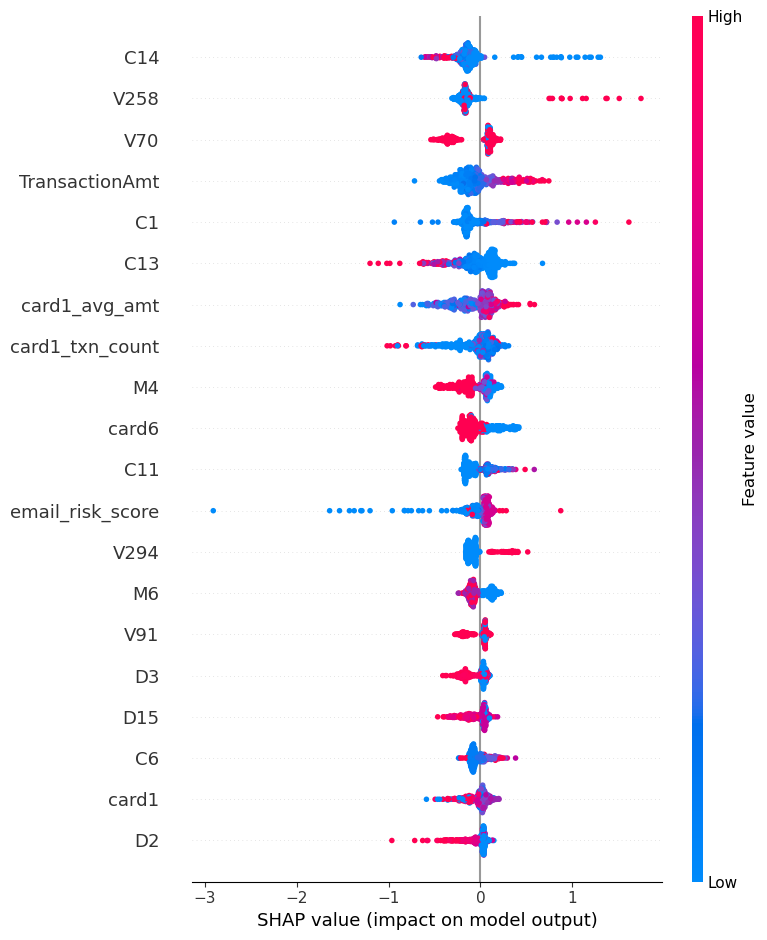

In [10]:
# Show the most important features according to SHAP
shap.summary_plot(shap_values, sample, max_display=20)

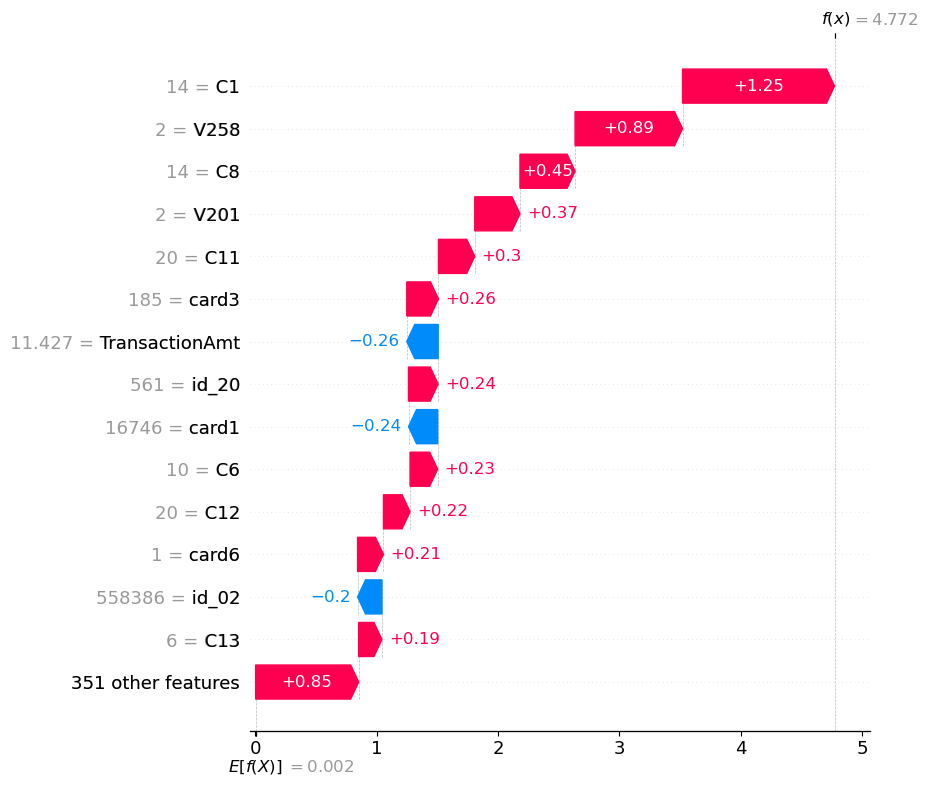

In [11]:
# Explain one specific fraud transaction
fraud_indices = y_test[y_test == 1].index
first_fraud = X_test[X_test.index == fraud_indices[0]]

# Get SHAP values for this one transaction
single_shap = explainer(first_fraud)

# Waterfall plot
shap.plots.waterfall(single_shap[0], max_display=15)